In [49]:
print("Hi")

Hi


In [50]:
from typing import (
    TypedDict,
    Literal,
    Annotated,
)

import operator

from dotenv import load_dotenv
from pydantic import BaseModel

In [51]:
from langchain_groq import ChatGroq
from langchain_core.messages import (
    HumanMessage,
    AIMessage,
)
from langchain_core.tools import tool
from langchain.agents import create_agent

from langgraph.graph import (
    StateGraph,
    START,
    END,
    MessagesState,
)
from langgraph.types import (
    Command,
    Send,
)
from langgraph.checkpoint.memory import InMemorySaver

In [52]:
load_dotenv()

True

In [53]:
model = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
)

In [54]:
def print_title(title: str):
    print("\n")
    print("=" * 80)
    print(title)
    print("=" * 80)

In [55]:
print_title("Multi-Agent Example")



Multi-Agent Example


In [56]:
def show_graph(compiled_graph):
    """Print the generated graph as Mermaid text."""
    print(compiled_graph.get_graph().draw_mermaid())

## 1. Router Multi-Agent

In [57]:
class RouterDecision(BaseModel):
    route: Literal[
        "technical",
        "billing",
        "general",
    ]

In [58]:
router_model = model.with_structured_output(RouterDecision)

In [59]:
router_model.invoke("can you resolve the bug in my system?")

RouterDecision(route='technical')

In [60]:
router_model.invoke("i have issue with payment, can you help me?")

RouterDecision(route='billing')

In [61]:
class RouterState(TypedDict):
    query: str
    route: str
    response: str

In [62]:
def router_node(state: RouterState,):

    decision = router_model.invoke(
        f"""
Route the following user query to exactly one specialist.

Available specialists:
- technical
- billing
- general

User query:
{state["query"]}
"""
    )

    return {
        "route": decision.route
    }

In [63]:
def technical_agent(state: RouterState):
    response = model.invoke(
        f"""
You are a technical support specialist.

Answer this query:
{state["query"]}
"""
    )

    return {
        "response": response.content
    }

In [64]:
def billing_agent(state: RouterState):
    response = model.invoke(
        f"""
You are a billing support specialist.

Answer this query:
{state["query"]}
"""
    )

    return {
        "response": response.content
    }

In [65]:
def general_agent(state: RouterState):
    response = model.invoke(
        f"""
You are a general support specialist.
Answer this query:
{state["query"]}
"""

    )
    return {
        "response": response.content
    }

In [66]:
def route_to_specialist(state: RouterState,):
    return state["route"]


### Build the graph


In [67]:
def build_router_multi_agent():
    builder = StateGraph(RouterState)
    
    builder.add_node(
        "router",
        router_node,
    )

    builder.add_node(
        "technical",
        technical_agent,
    )

    builder.add_node(
        "billing",
        billing_agent,
    )

    builder.add_node(
        "general",
        general_agent,
    )

    builder.add_edge(
        START,
        "router",
    )

    builder.add_conditional_edges(
        "router",
        route_to_specialist,
        {
            "technical": "technical",
            "billing": "billing",
            "general": "general",
        },
    )

    builder.add_edge(
        "technical",
        END,
    )

    builder.add_edge(
        "billing",
        END,
    )

    builder.add_edge(
        "general",
        END,
    )

    return builder.compile()


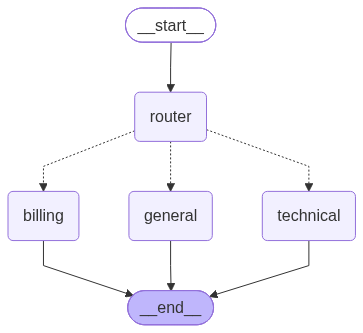

In [68]:
router_graph  = build_router_multi_agent();
router_graph

In [69]:
def run_router_multi_agent():

    print_title(
        "1. ROUTER MULTI-AGENT"
    )

    graph = (build_router_multi_agent())

    result = graph.invoke(
        {
            "query":"My subscription payment was charged twice.",
            "route": "",
            "response": "",
        }
    )

    print(
        "Selected Agent:",
        result["route"],
    )

    print(
        "\nResponse:\n",
        result["response"],
    )

    return result


In [70]:
router_result = run_router_multi_agent()




1. ROUTER MULTI-AGENT
Selected Agent: billing

Response:
 Hi there,

I’m sorry to hear that you’ve been charged twice for your subscription. Let’s get this sorted out right away.

### What I need from you
1. **Date(s) of the duplicate charge(s)**  
2. **Amount(s) charged**  
3. **Transaction ID(s)** (if you can see them on your bank statement or in your email receipt)  
4. **The email address** associated with the subscription

You can reply to this message with the details above, or if you prefer, you can also send a screenshot of the bank statement (just make sure to blur any sensitive info).

### What I’ll do
- **Verify** the duplicate charge in our system.  
- If it’s indeed a duplicate, I’ll **initiate a refund** for the extra amount.  
- I’ll also **confirm** that your subscription remains active and that no other charges will occur.

### Timeline
- **Refund processing** usually takes 3–5 business days to appear on your statement, depending on your bank.  
- I’ll send you a con

## 2. Subagents / Agent-as-Tool

In [71]:
from langchain.agents import create_agent

In [72]:
research_subagent = create_agent(
    model=model,
    tools=[],
    system_prompt=(
        "You are a research specialist. "
        "Provide concise factual research."
    ),
    name="research_subagent",
)

In [73]:
math_subagent = create_agent(
    model=model,
    tools=[],
    system_prompt=(
        "You are a math specialist. "
        "Solve calculations accurately."
    ),
    name="math_subagent",
)

In [74]:
writing_subagent = create_agent(
    model=model,
    tools=[],
    system_prompt=(
        "You are a professional writing specialist. "
        "Rewrite information clearly and concisely."
    ),
    name="writing_subagent",
)

In [75]:
def get_last_message_content(result,):

    return (
        result["messages"][-1].content
    )

In [76]:
@tool
def ask_research_agent(task: str) -> str:
    """
    Delegate a research task to the research specialist.
    """

    result = research_subagent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": task,
                }
            ]
        }
    )

    return get_last_message_content(
        result
    )

In [77]:
@tool
def ask_math_agent(task: str) -> str:
    """
    Delegate a math task to the math specialist.
    """

    result = math_subagent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": task,
                }
            ]
        }
    )

    return get_last_message_content(
        result
    )


In [78]:
@tool
def ask_math_agent(
    task: str,
) -> str:
    """
    Delegate a mathematical task to the math specialist.
    """

    result = math_subagent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": task,
                }
            ]
        }
    )

    return get_last_message_content(
        result
    )

In [79]:
@tool
def ask_writing_agent(
    task: str,
) -> str:
    """
    Delegate a writing task to the writing specialist.
    """

    result = writing_subagent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": task,
                }
            ]
        }
    )

    return get_last_message_content(
        result
    )

In [80]:
main_delegation_agent = create_agent(
    model=model,
    tools=[
        ask_research_agent,
        ask_math_agent,
        ask_writing_agent,
    ],
    system_prompt="""
You are the main coordinator.

You have three specialist subagents:
1. Research specialist
2. Math specialist
3. Writing specialist

Delegate work to the appropriate specialist tools.
You may call multiple specialists when necessary.
Finally provide one clear answer to the user.
""",
    name="main_coordinator",
)

In [81]:
show_graph(main_delegation_agent)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



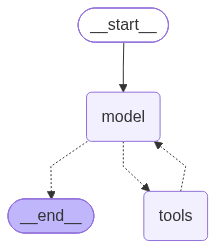

In [82]:
main_delegation_agent

In [83]:
def run_subagents():

    print_title(
        "2. SUBAGENTS / AGENT-AS-TOOL"
    )

    result = (
        main_delegation_agent.invoke(
            {
                "messages": [
                    {
                        "role": "user",
                        "content": (
                            "Explain RAG briefly, calculate "
                            "25 * 16, and present the answer "
                            "in a clean professional format."
                        ),
                    }
                ]
            }
        )
    )

    print(
        result["messages"][-1].content
    )

    return result


In [84]:
subagents_result = run_subagents()




2. SUBAGENTS / AGENT-AS-TOOL
**Retrieval‑Augmented Generation (RAG)**  
RAG is a hybrid natural‑language‑processing framework that combines a *retrieval* component with a *generation* component to produce responses that are both fluent and factually grounded.

| Component | Function |
|-----------|----------|
| **Retriever** | Searches an external knowledge base (e.g., Wikipedia, corporate documents) and returns the most relevant passages for a given query. |
| **Generator** | A language model (e.g., BART, T5, GPT) that receives the query **plus** the retrieved passages and generates the final answer. |
| **Training** | Jointly fine‑tunes the retriever and generator on query–answer pairs, often using a retrieval‑augmented loss to encourage evidence usage. |
| **Inference** | For a new query, the system first retrieves evidence, then conditions the generator on that evidence to produce a response that is both fluent and grounded. |

**Key Advantages**

- **Up‑to‑date knowledge** – The

In [85]:
subagents_result

{'messages': [HumanMessage(content='Explain RAG briefly, calculate 25 * 16, and present the answer in a clean professional format.', additional_kwargs={}, response_metadata={}, id='97d2f330-82be-446b-9490-fa6649323908'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to delegate tasks: RAG explanation (research), calculation (math), and formatting (writing). We'll call research for RAG explanation, math for multiplication, writing for formatting. Then combine.", 'tool_calls': [{'id': 'fc_5f9a6350-8ee4-4ce3-b135-c0e33f6f4e9e', 'function': {'arguments': '{"task":"Explain Retrieval-Augmented Generation (RAG) briefly."}', 'name': 'ask_research_agent'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 76, 'prompt_tokens': 253, 'total_tokens': 329, 'completion_time': 0.079671507, 'completion_tokens_details': {'reasoning_tokens': 41}, 'prompt_time': 0.012289468, 'prompt_tokens_details': None, 'queue_time': 0.231205981, 'total_time': 0.09

In [86]:
subagents_result['messages'][-1].content

'**Retrieval‑Augmented Generation (RAG)**  \nRAG is a hybrid natural‑language‑processing framework that combines a *retrieval* component with a *generation* component to produce responses that are both fluent and factually grounded.\n\n| Component | Function |\n|-----------|----------|\n| **Retriever** | Searches an external knowledge base (e.g., Wikipedia, corporate documents) and returns the most relevant passages for a given query. |\n| **Generator** | A language model (e.g., BART, T5, GPT) that receives the query **plus** the retrieved passages and generates the final answer. |\n| **Training** | Jointly fine‑tunes the retriever and generator on query–answer pairs, often using a retrieval‑augmented loss to encourage evidence usage. |\n| **Inference** | For a new query, the system first retrieves evidence, then conditions the generator on that evidence to produce a response that is both fluent and grounded. |\n\n**Key Advantages**\n\n- **Up‑to‑date knowledge** – The retriever can pul

## 3. Supervisor Multi-Agent

In [87]:
class SupervisorDecision(BaseModel):

    next_agent: Literal[
        "research_agent",
        "math_agent",
        "writer_agent",
        "FINISH",
    ]

    instruction: str

In [88]:
class SupervisorState(TypedDict):
    task: str
    next_agent: str
    instruction: str
    worker_outputs: Annotated[
        list[str],
        operator.add,
    ]
    final_answer: str
    supervisor_turns: int

In [89]:
supervisor_router = (
    model.with_structured_output(
        SupervisorDecision
    )
)

In [90]:
supervisor_router.invoke("can you research about the RAG?")

SupervisorDecision(next_agent='research_agent', instruction='Research about Retrieval-Augmented Generation (RAG) including its architecture, use cases, advantages, limitations, and recent developments.')

In [91]:
def supervisor(
    state: SupervisorState,
):

    supervisor_turns = state.get(
        "supervisor_turns",
        0,
    ) + 1

    completed_work = "\n\n".join(
        state.get(
            "worker_outputs",
            [],
        )
    )

    if supervisor_turns >= 6 and completed_work:
        return {
            "next_agent": "FINISH",
            "instruction": (
                "Maximum supervisor turns reached. "
                "Create the final answer."
            ),
            "supervisor_turns": supervisor_turns,
        }

    decision = supervisor_router.invoke(
        f"""
You are a supervisor managing three workers:

- research_agent
- math_agent
- writer_agent

Original task:
{state["task"]}

Work completed so far:
{completed_work or "No worker has completed any work yet."}

Choose the next worker.

Rules:
- Use research_agent for research/explanation.
- Use math_agent for calculations.
- Use writer_agent when a polished final presentation is useful.
- If enough work is complete, choose FINISH.
- Do not repeatedly call the same worker unless required.

Return:
- next_agent
- instruction for that worker
"""
    )

    return {
        "next_agent":
        decision.next_agent,

        "instruction":
        decision.instruction,

        "supervisor_turns":
        supervisor_turns,
    }


In [92]:
def supervisor_research_worker(
    state: SupervisorState,
):

    response = model.invoke(
        f"""
You are the research worker.

Original task:
{state["task"]}

Supervisor instruction:
{state["instruction"]}

Perform only the research/explanation part.
"""
    )

    return {
        "worker_outputs": [
            "RESEARCH WORKER:\n"
            + response.content
        ]
    }

In [93]:
def supervisor_math_worker(
    state: SupervisorState,
):

    response = model.invoke(
        f"""
You are the math worker.

Original task:
{state["task"]}

Supervisor instruction:
{state["instruction"]}

Perform only the calculation/reasoning part.
"""
    )

    return {
        "worker_outputs": [
            "MATH WORKER:\n"
            + response.content
        ]
    }



In [94]:
def supervisor_writer_worker(
    state: SupervisorState,
):

    previous_work = "\n\n".join(
        state.get(
            "worker_outputs",
            [],
        )
    )

    response = model.invoke(
        f"""
You are the writing worker.

Original task:
{state["task"]}

Supervisor instruction:
{state["instruction"]}

Available previous work:
{previous_work}

Create a polished response or writing contribution.
"""
    )

    return {
        "worker_outputs": [
            "WRITER WORKER:\n"
            + response.content
        ]
    }

In [95]:
def supervisor_finish(
    state: SupervisorState,
):

    completed_work = "\n\n".join(
        state["worker_outputs"]
    )

    response = model.invoke(
        f"""
You are the supervisor.

Create the final answer for the user.

Original task:
{state["task"]}

Worker outputs:
{completed_work}
"""
    )

    return {
        "final_answer":
        response.content
    }

In [96]:
def supervisor_route(
    state: SupervisorState,
):

    return state["next_agent"]

In [97]:
def build_supervisor_graph():

    builder = StateGraph(
        SupervisorState
    )

    builder.add_node(
        "supervisor",
        supervisor,
    )

    builder.add_node(
        "research_agent",
        supervisor_research_worker,
    )

    builder.add_node(
        "math_agent",
        supervisor_math_worker,
    )

    builder.add_node(
        "writer_agent",
        supervisor_writer_worker,
    )

    builder.add_node(
        "finish",
        supervisor_finish,
    )

    builder.add_edge(
        START,
        "supervisor",
    )

    builder.add_conditional_edges(
        "supervisor",
        supervisor_route,
        {
            "research_agent":
            "research_agent",

            "math_agent":
            "math_agent",

            "writer_agent":
            "writer_agent",

            "FINISH":
            "finish",
        },
    )

    builder.add_edge(
        "research_agent",
        "supervisor",
    )

    builder.add_edge(
        "math_agent",
        "supervisor",
    )

    builder.add_edge(
        "writer_agent",
        "supervisor",
    )

    builder.add_edge(
        "finish",
        END,
    )

    return builder.compile()


In [98]:
supervisor_graph = build_supervisor_graph()
show_graph(supervisor_graph)


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	research_agent(research_agent)
	math_agent(math_agent)
	writer_agent(writer_agent)
	finish(finish)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	math_agent --> supervisor;
	research_agent --> supervisor;
	supervisor -. &nbsp;FINISH&nbsp; .-> finish;
	supervisor -.-> math_agent;
	supervisor -.-> research_agent;
	supervisor -.-> writer_agent;
	writer_agent --> supervisor;
	finish --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



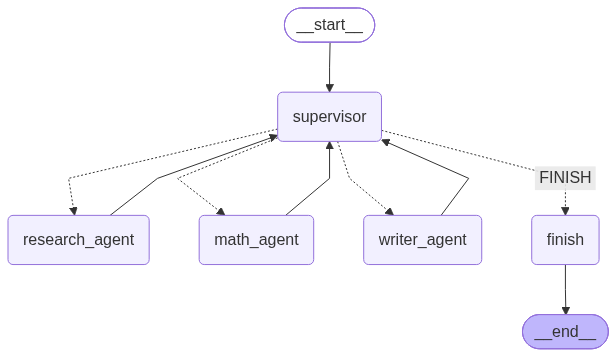

In [99]:
supervisor_graph

In [102]:
def run_supervisor():

    print_title(
        "3. SUPERVISOR MULTI-AGENT"
    )

    graph = build_supervisor_graph()

    result = graph.invoke(
        {
            "task": (
                "Explain Retrieval-Augmented Generation, "
                "calculate 48 * 25, and present everything "
                "as a short training note."
            ),

            "next_agent": "",
            "instruction": "",
            "worker_outputs": [],
            "final_answer": "",
            "supervisor_turns": 0,
        },

        config={
            "recursion_limit": 20
        },
    )

    print(
        result["final_answer"]
    )

    return result


In [103]:
supervisor_result = run_supervisor()




3. SUPERVISOR MULTI-AGENT
**Retrieval‑Augmented Generation (RAG) – Quick Training Note**

| Topic | Key Points |
|-------|------------|
| **What it is** | A hybrid NLP framework that *retrieves* relevant passages from an external knowledge base and *generates* an answer with a language model. |
| **Why use it?** | • **Up‑to‑date knowledge** – pulls fresh facts that the base model may not know.<br>• **Reduced hallucination** – grounding in real documents lowers fabricated content.<br>• **Domain‑specific scaling** – no full‑model retraining needed. |
| **Core Workflow** | 1. **Query formulation** – turn the prompt into a search query.<br>2. **Document retrieval** – use BM25, DPR, or similar to fetch top‑k passages.<br>3. **Fusion** – concatenate or encode passages with the prompt (token‑ or sequence‑level).<br>4. **Generation** – a transformer (e.g., GPT, BART) produces the final answer conditioned on the fused input. |
| **Typical Architectures** | • **RAG‑Token** – passages added as 